# Lab 2: LangGraph, the orchestration layer

Today we learn how a graph works without calling an LLM at all. LangGraph does not care what runs inside a node, so we can master the mechanics first: **state, reducers, nodes, edges and the loop**. In Lab 3 we swap the fake workers for LLM calls.

The agent we are heading for looks like this:

```
START -> plan -> execute --(more tasks?)--> execute
                    |
                    +--(all done)--> build -> END
```

In [1]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.errors import GraphRecursionError


def show(graph):
    """Draw the graph. The PNG render needs internet, so fall back to Mermaid text."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## State, and a word about reducers

The state is the object that flows through the graph, described by a `TypedDict`. Each field updates on its own, and by default **a new value replaces the old one**.

Sometimes we want updates to **accumulate**. A reducer says how to combine the old value with the new one, and we attach it with `Annotated`. `operator.add` on a list means "append". We will use this for the finished sections.

First, the version without a reducer, so you can see the problem it solves.

In [2]:
class OverwriteState(TypedDict):
    done: list           # no reducer: every update replaces the old value


def worker_overwrite(state: OverwriteState) -> dict:
    return {"done": ["finished one task"]}


b = StateGraph(OverwriteState)
b.add_node("worker", worker_overwrite)
b.add_edge(START, "worker")
b.add_edge("worker", END)
print(b.compile().invoke({"done": ["old item"]}))

{'done': ['finished one task']}


The `"old item"` is gone: the node's update replaced it. Now with a reducer.

In [3]:
class AppendState(TypedDict):
    done: Annotated[list, operator.add]    # reducer: updates are appended


def worker_append(state: AppendState) -> dict:
    return {"done": ["finished one task"]}


b = StateGraph(AppendState)
b.add_node("worker", worker_append)
b.add_edge(START, "worker")
b.add_edge("worker", END)
print(b.compile().invoke({"done": ["old item"]}))

{'done': ['old item', 'finished one task']}


Both items survive. A node returns *only the new part*, and the reducer does the combining. This is the cleanest way to collect sections, and it avoids the classic bug of mutating a list inside a node.

## The loop: nodes, edges and a conditional edge

Our executor handles **one task per visit**. To process a whole TODO list, a **conditional edge** after the worker asks "are there more tasks?" and either routes back to the worker or on to the end. State holds the list of todos and a counter.

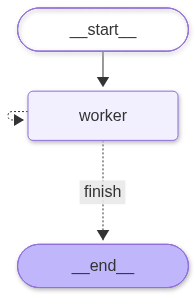

In [4]:
class LoopState(TypedDict):
    todos: list[str]                       # the TODO list
    current: int                           # which todo we are on
    done: Annotated[list, operator.add]    # finished work, appended each visit


def worker(state: LoopState) -> dict:
    task = state["todos"][state["current"]]
    print(f"  worker doing todo {state['current'] + 1}/{len(state['todos'])}: {task}")
    return {"done": [f"finished: {task}"], "current": state["current"] + 1}


def more_work(state: LoopState) -> str:
    return "worker" if state["current"] < len(state["todos"]) else "finish"


b = StateGraph(LoopState)
b.add_node("worker", worker)
b.add_edge(START, "worker")
b.add_conditional_edges("worker", more_work, {"worker": "worker", "finish": END})
loop_graph = b.compile()

show(loop_graph)

In [5]:
result = loop_graph.invoke({"todos": ["Intro", "Scope", "Risks", "Timeline"], "current": 0, "done": []})
print(result["done"])

  worker doing todo 1/4: Intro
  worker doing todo 2/4: Scope
  worker doing todo 3/4: Risks
  worker doing todo 4/4: Timeline
['finished: Intro', 'finished: Scope', 'finished: Risks', 'finished: Timeline']


The graph visited the worker four times with no code that says "four". The list length decides. **That is the autonomous part of our agent:** the model will write the TODO list, and the loop adapts to however long that list is.

## Watching it work: streaming

`stream` yields the update from each node as it finishes. In the live demo this is a great way to show the agent working step by step.

In [7]:
for step in loop_graph.stream({"todos": ["Intro", "Risks"], "current": 0, "done": []}, stream_mode="updates"):
    print(step)

  worker doing todo 1/2: Intro
{'worker': {'done': ['finished: Intro'], 'current': 1}}
  worker doing todo 2/2: Risks
{'worker': {'done': ['finished: Risks'], 'current': 2}}


## Safety net: the recursion limit

A loop with a bug can run forever. LangGraph stops a run after a number of steps called the recursion limit (the default is 25). We pass our own so a runaway plan fails fast instead of burning API credits. Here we give it a long TODO list and a tiny limit on purpose.

In [6]:
try:
    loop_graph.invoke(
        {"todos": [f"task {i}" for i in range(10)], "current": 0, "done": []},
        config={"recursion_limit": 5},
    )
except GraphRecursionError as error:
    print("Stopped by the safety net:", str(error)[:100])

  worker doing todo 1/10: task 0
  worker doing todo 2/10: task 1
  worker doing todo 3/10: task 2
  worker doing todo 4/10: task 3
  worker doing todo 5/10: task 4
Stopped by the safety net: Recursion limit of 5 reached without hitting a stop condition. You can increase the limit by setting


Note for Lab 3: the real limit must be larger than `7 tasks + plan + build`. We use 50.

## Where an LLM plugs in

A node is just a function from state to a partial state update, so swapping `worker` for a function that calls `ask(Section, ...)` changes nothing about the graph. That is the whole of Lab 3.

You could also add a **checkpointer** (`MemorySaver`) so the graph remembers across calls under a `thread_id`. Our agent does one job per request, so we do not need it, and leaving it out keeps the design simple. Say that in the tradeoff part of your video.

## Recap

State with a reducer, nodes, edges, a conditional edge that makes a loop, streaming and the recursion limit. You have now built the exact skeleton of the agent.

### Exercise


Add a second conditional edge: if a todo contains the word "skip", route straight to `END` instead of looping. Then add a `plan` node before the worker that builds the `todos` list itself from a request string, using plain Python (no LLM yet). You have just written the shape of Lab 3.